In [19]:
%pip install ultralytics

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: ultralytics in c:\users\karen hany\appdata\local\programs\python\python310\lib\site-packages (8.4.21)




[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import json
import random
import shutil
import numpy as np

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

In [3]:
import torch

print(torch.cuda.is_available())

if torch.cuda.is_available():

    print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [4]:
from pathlib import Path
import os

EXTRACT_DIR = Path(
    r"D:\Projects\DeepLearning\YOLO_Disaster_Project\xbd"
)

EXTRACT_DIR.mkdir(
    exist_ok=True
)

print(EXTRACT_DIR)

D:\Projects\DeepLearning\YOLO_Disaster_Project\xbd


In [5]:
import tarfile

TRAIN_TAR = r"D:\Projects\DeepLearning\YOLO_Disaster_Project\datasets\train_images_labels_targets.tar"

TEST_TAR = r"D:\Projects\DeepLearning\YOLO_Disaster_Project\datasets\test_images_labels_targets.tar"

# Extract train
with tarfile.open(TRAIN_TAR) as tar:

    tar.extractall(EXTRACT_DIR)

print("Train extracted")

# Extract test
with tarfile.open(TEST_TAR) as tar:

    tar.extractall(EXTRACT_DIR)

print("Test extracted")

Train extracted
Test extracted


In [6]:
print(os.listdir(EXTRACT_DIR))

['test', 'train']


In [7]:
TRAIN_DIR = EXTRACT_DIR / "train"

images = list(
    (TRAIN_DIR / "images").glob("*.png")
)

print("Train images:", len(images))

Train images: 5598


In [8]:
import json
from collections import Counter
from pathlib import Path

TRAIN_DIR = Path(
    r"D:\Projects\DeepLearning\YOLO_Disaster_Project\xbd\train"
)

label_dir = TRAIN_DIR / "labels"

damage_counter = Counter()

json_files = list(label_dir.glob("*.json"))

print("JSON files:", len(json_files))

for json_path in json_files:

    with open(json_path, "r") as f:

        data = json.load(f)

    features = data["features"]["xy"]

    for feature in features:

        props = feature["properties"]

        subtype = props.get("subtype")

        if subtype:

            damage_counter[subtype] += 1

print("\nDamage Distribution:\n")

for cls, count in damage_counter.items():

    print(f"{cls}: {count}")

JSON files: 5598

Damage Distribution:

no-damage: 117426
minor-damage: 14980
destroyed: 13227
major-damage: 14161
un-classified: 2993


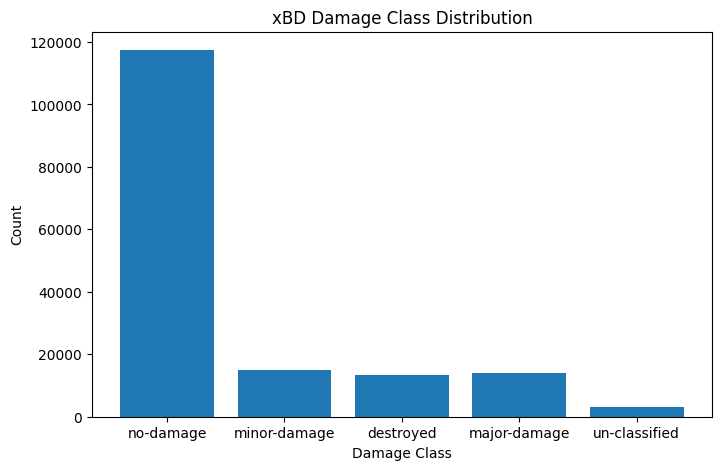

In [9]:
import matplotlib.pyplot as plt

classes = list(damage_counter.keys())

counts = list(damage_counter.values())

plt.figure(figsize=(8,5))

plt.bar(classes, counts)

plt.title("xBD Damage Class Distribution")

plt.xlabel("Damage Class")

plt.ylabel("Count")

plt.show()

In [10]:
from pathlib import Path

SEG_DIR = Path(
    r"D:\Projects\DeepLearning\YOLO_Disaster_Project\balanced_seg_dataset"
)

for split in ["train", "val"]:

    (SEG_DIR / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (SEG_DIR / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

print("Folders created")

Folders created


In [11]:
from sklearn.model_selection import train_test_split

all_images = list(
    (TRAIN_DIR / "images").glob("*post_disaster.png")
)

train_imgs, val_imgs = train_test_split(

    all_images,

    test_size=0.2,

    random_state=42
)

print("Train:", len(train_imgs))
print("Val:", len(val_imgs))

Train: 2239
Val: 560


In [12]:
import json
import random
import shutil

MAX_NO_DAMAGE = 25000

damage_counts = {
    "no-damage": 0,
    "minor-damage": 0,
    "major-damage": 0,
    "destroyed": 0
}

DAMAGE_TO_ID = {
    "no-damage": 0,
    "minor-damage": 1,
    "major-damage": 2,
    "destroyed": 3
}

In [13]:
def convert_segmentation_split(images_list, split_name):

    global damage_counts

    for img_path in images_list:

        json_path = (
            TRAIN_DIR
            / "labels"
            / f"{img_path.stem}.json"
        )

        if not json_path.exists():
            continue

        with open(json_path, "r") as f:

            data = json.load(f)

        features = data["features"]["xy"]

        image = Image.open(img_path)

        width, height = image.size

        yolo_lines = []

        for feature in features:

            props = feature["properties"]

            subtype = props.get("subtype")

            if subtype == "un-classified":
                continue

            if subtype not in DAMAGE_TO_ID:
                continue

            # BALANCE no-damage
            if subtype == "no-damage":

                if damage_counts["no-damage"] >= MAX_NO_DAMAGE:
                    continue

            class_id = DAMAGE_TO_ID[subtype]

            wkt = feature["wkt"]

            coords = (
                wkt.replace("POLYGON ((", "")
                   .replace("))", "")
            )

            polygon_points = []

            for pair in coords.split(","):

                x, y = pair.strip().split(" ")

                x = float(x) / width
                y = float(y) / height

                polygon_points.extend([x, y])

            if len(polygon_points) < 6:
                continue

            line = (
                str(class_id)
                + " "
                + " ".join(map(str, polygon_points))
            )

            yolo_lines.append(line)

            damage_counts[subtype] += 1

        # skip empty labels
        if len(yolo_lines) == 0:
            continue

        # copy image
        shutil.copy(

            img_path,

            SEG_DIR
            / "images"
            / split_name
            / img_path.name
        )

        # save label
        label_path = (
            SEG_DIR
            / "labels"
            / split_name
            / f"{img_path.stem}.txt"
        )

        with open(label_path, "w") as f:

            f.write("\n".join(yolo_lines))

    print(f"{split_name} conversion done")

In [14]:
convert_segmentation_split(
    train_imgs,
    "train"
)

convert_segmentation_split(
    val_imgs,
    "val"
)

train conversion done
val conversion done


In [15]:
print(damage_counts)

{'no-damage': 25000, 'minor-damage': 14980, 'major-damage': 14161, 'destroyed': 13227}


In [16]:
yaml_text = f"""
path: {SEG_DIR}

train: images/train
val: images/val

names:
  0: no-damage
  1: minor-damage
  2: major-damage
  3: destroyed
"""

yaml_path = SEG_DIR / "seg_data.yaml"

with open(yaml_path, "w") as f:

    f.write(yaml_text)

print("Saved:", yaml_path)

Saved: D:\Projects\DeepLearning\YOLO_Disaster_Project\balanced_seg_dataset\seg_data.yaml


In [5]:
from pathlib import Path

yaml_path = Path(
    r"D:\Projects\DeepLearning\YOLO_Disaster_Project\seg_data.yaml"
)

print(yaml_path)

D:\Projects\DeepLearning\YOLO_Disaster_Project\seg_data.yaml


In [6]:
from ultralytics import YOLO

model = YOLO("yolov8n-seg.pt")   # smaller + much faster

results = model.train(

    data=str(yaml_path),

    epochs=50,                   # instead of 120

    imgsz=640,                   # HUGE speed improvement

    batch=4,                     # better for 6GB GPU

    workers=2,

    device=0,

    optimizer="AdamW",

    lr0=0.001,

    patience=15,

    project=r"D:\Projects\DeepLearning\YOLO_Disaster_Project\runs",

    name="xbd_segmentation_fast",

    pretrained=True,

    save=True,

    save_period=10,

    mosaic=0.5,                  # lighter augmentation

    mixup=0.0,                   # disable for speed/stability

    fliplr=0.5,

    flipud=0.0                   # remove vertical flip
)

New https://pypi.org/project/ultralytics/8.4.48 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.21  Python-3.10.11 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Projects\DeepLearning\YOLO_Disaster_Project\seg_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, mome

c:\Users\Karen Hany\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access  (ping: 0.00.0 ms, read: 1513.9778.7 MB/s, size: 1259.1 KB)
val: Scanning D:\Projects\DeepLearning\YOLO_Disaster_Project\balanced_seg_dataset\labels\val.cache... 298 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 298/298  0.0s
optimizer: AdamW(lr=0.001, momentum=0.937) with parameter groups 66 weight(decay=0.0), 77 weight(decay=0.0005), 76 bias(decay=0.0)
Plotting labels to D:\Projects\DeepLearning\YOLO_Disaster_Project\runs\xbd_segmentation_fast4\labels.jpg... 
Image sizes 640 train, 640 val
Using 2 dataloader workers
Logging results to D:\Projects\DeepLearning\YOLO_Disaster_Project\runs\xbd_segmentation_fast4
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
   